<a href="https://colab.research.google.com/github/fadilaha/Sentiment-Forecast/blob/main/sentiment_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment forecasting: XGBoost vs LightGBM vs VAR

Run the cells from top to bottom. Each model has its own cell (steps 6, 7, 8),
so you can run, change or re-run one model without touching the others.

1. Settings: **edit this cell** (column names, timezone)
2. Libraries
3. Load and merge the monthly files
4. Group posts into time bins + overview plot
5. Shared tools (features, walk-forward test, scoring) + the "no change" baseline
6. XGBoost
7. LightGBM
8. VAR
9. Compare all models + save results

## 1. Settings

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
USE_DRIVE   = True
PROJECT_DIR = '/content/drive/MyDrive/sentiment_project'   # folder on the Drive
DATA_FOLDER = 'Raw Data'               # subfolder containing the monthly files (csv / xlsx)

TIME_COL  = 'Date'           # timestamp column name in the files
LABEL_COL = 'Sentiment'            # sentiment label column name
INPUT_TZ  = 'Asia/Jakarta'         # timezone of the timestamps in the files
LOCAL_TZ  = 'Asia/Jakarta'         # timezone used for binning (WIB)

TARGET     = 'net'                 # 'net' = (pos - neg)/n, or 'share_pos', 'share_neu', 'share_neg'
FREQS      = ['1h', '6h', '12h', '1D']
HORIZONS_H = [1, 6, 12, 24, 72, 168]   # forecast horizons in hours. Horizons: how far the duration of time that will be predicted.
TEST_START = None                  # e.g. '2026-05-01'; None = first day of the last month
FOLD_DAYS  = 3                     # retrain every 3 days during the test period. Every 3 days, the models are retrained from scratch using all the data available up to that point.
OUT_DIR    = 'results'

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
import os
os.chdir(PROJECT_DIR)
print('Working in', os.getcwd(), '| files in data:', sorted(os.listdir(DATA_FOLDER)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/MyDrive/sentiment_project | files in data: ['prabowo26_agustus.xlsx', 'prabowo26_april.xlsx', 'prabowo26_februari.xlsx', 'prabowo26_januari.xlsx', 'prabowo26_juli.xlsx', 'prabowo26_juni.xlsx', 'prabowo26_maret.xlsx', 'prabowo26_mei.xlsx', 'prabowo26_sept.xlsx']


## 2. Libraries

In [4]:
!pip install -q xgboost lightgbm
import glob, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import lightgbm as lgb
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='X does not have valid feature names')
print('xgboost', xgb.__version__, '| lightgbm', lgb.__version__)

xgboost 3.4.1 | lightgbm 4.6.0


## 3. Load and merge the monthly files
Check the printout to ensure that every month present, few (to no) unreadable timestamps, and all label values are recognised.

In [5]:
LABEL_MAP = {
    'positive': 1, 'positif': 1, 'pos': 1, '1': 1, '1.0': 1, '+1': 1,
    'neutral': 0, 'netral': 0, 'neu': 0, '0': 0, '0.0': 0,
    'negative': -1, 'negatif': -1, 'neg': -1, '-1': -1, '-1.0': -1,
}
cols = [TIME_COL, LABEL_COL]

def read_any(path):
    """Read a file, finding the header row automatically (e.g. when row 1 is empty)."""
    p = path.lower()
    if p.endswith('.parquet'):
        return pd.read_parquet(path, columns=cols)
    is_xl = p.endswith(('.xlsx', '.xls'))
    peek = (pd.read_excel(path, header=None, nrows=20) if is_xl
            else pd.read_csv(path, header=None, nrows=20))
    hdr = next((i for i, r in peek.iterrows()
                if set(cols) <= set(r.astype(str).str.strip())), None)
    if hdr is None:
        raise ValueError(f'{os.path.basename(path)}: could not find columns {cols} in the first '
                         f'20 rows. Check the names in the settings cell (they are case-sensitive).')
    d = (pd.read_excel(path, header=hdr) if is_xl else pd.read_csv(path, header=hdr))
    d.columns = d.columns.astype(str).str.strip()
    return d[cols]

files = sorted(f for f in glob.glob(os.path.join(DATA_FOLDER, '*'))
               if f.lower().endswith(('.csv', '.xlsx', '.xls', '.parquet')))
parts = []
for f in files:
    d = read_any(f)
    print(f'{os.path.basename(f):40s} {len(d):>10,} rows')
    parts.append(d)
raw = pd.concat(parts, ignore_index=True)

t = pd.to_datetime(raw[TIME_COL], errors='coerce', format='mixed')
if t.dt.tz is None:
    t = t.dt.tz_localize(INPUT_TZ, ambiguous='NaT', nonexistent='NaT')
t = t.dt.tz_convert(LOCAL_TZ)
lab = raw[LABEL_COL].astype(str).str.strip().str.lower().map(LABEL_MAP)

print(f'\nTotal rows: {len(raw):,} | unreadable timestamps: {t.isna().sum():,} '
      f'| unrecognised labels: {lab.isna().sum():,}')
if lab.isna().any():
    print('  examples of unrecognised labels:', raw.loc[lab.isna(), LABEL_COL].astype(str).unique()[:10])
posts = pd.DataFrame({'time': t, 'label': lab}).dropna()
posts['label'] = posts['label'].astype(int)
del raw, parts, t, lab

print(f'Kept {len(posts):,} posts, {posts.time.min()} -> {posts.time.max()}')
print('\nPosts per month:')
print(posts.time.dt.tz_localize(None).dt.to_period('M').value_counts().sort_index().to_string())
print('\nLabels:', posts.label.map({1: 'positive', 0: 'neutral', -1: 'negative'}).value_counts().to_dict())
print('\nPosts by hour of day (should be low at night if the timezone is right):')
print(posts.time.dt.hour.value_counts().sort_index().to_string())

prabowo26_agustus.xlsx                      330,158 rows
prabowo26_april.xlsx                        257,472 rows
prabowo26_februari.xlsx                     323,114 rows
prabowo26_januari.xlsx                      274,181 rows
prabowo26_juli.xlsx                         323,615 rows
prabowo26_juni.xlsx                         409,684 rows
prabowo26_maret.xlsx                        249,443 rows
prabowo26_mei.xlsx                          342,500 rows
prabowo26_sept.xlsx                         331,667 rows

Total rows: 2,841,834 | unreadable timestamps: 0 | unrecognised labels: 0
Kept 2,841,834 posts, 2026-01-01 00:00:00+07:00 -> 2026-09-30 23:59:47+07:00

Posts per month:
time
2026-01    274181
2026-02    323114
2026-03    249443
2026-04    257472
2026-05    342500
2026-06    409684
2026-07    323615
2026-08    330158
2026-09    331667
Freq: M

Labels: {'negative': 1346201, 'positive': 1148333, 'neutral': 347300}

Posts by hour of day (should be low at night if the timezone is right)

## 4. Group posts into time bins

The posts's sentiment is counted (Positive-Negative/N) per hour, per 6 hours, per 12 hours, and per day. The graph shown in this cell is the actual data from January to September. The part that will be predicted and tested is the start of September (marked by dashed line).

  1h:  6,504 bins | posts per bin: median 400, min 0 | empty bins 0.1%
  6h:  1,084 bins | posts per bin: median 2510, min 262 | empty bins 0.0%
 12h:    542 bins | posts per bin: median 4862, min 1916 | empty bins 0.0%
  1D:    271 bins | posts per bin: median 10014, min 4340 | empty bins 0.0%

Training data: before 2026-09-01 | test: 2026-09-01 onwards


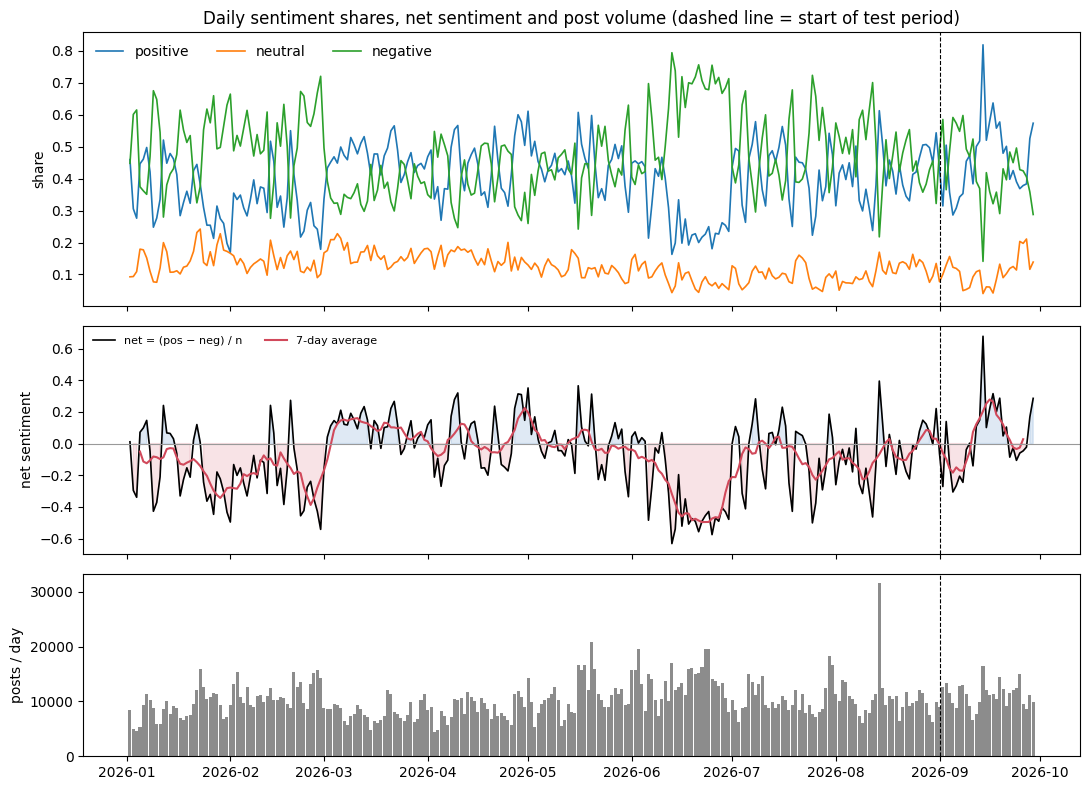

In [6]:
FREQ_HOURS = {'1h': 1, '3h': 3, '6h': 6, '12h': 12, '1d': 24}

def aggregate(posts, freq):
    start = posts.time.min().normalize() + pd.Timedelta(days=1)   # complete days only
    end = posts.time.max().normalize()
    p = posts[(posts.time >= start) & (posts.time < end)]
    counts = p.groupby([pd.Grouper(key='time', freq=freq), 'label']).size().unstack(fill_value=0)
    idx = pd.date_range(start, end, freq=freq, inclusive='left')
    counts = counts.reindex(idx, fill_value=0)
    for k in (-1, 0, 1):
        if k not in counts.columns:
            counts[k] = 0
    a = pd.DataFrame(index=idx)
    a['n_neg'], a['n_neu'], a['n_pos'] = counts[-1], counts[0], counts[1]
    a['n'] = a[['n_neg', 'n_neu', 'n_pos']].sum(axis=1)
    nz = a['n'].replace(0, np.nan)
    a['share_pos'], a['share_neu'], a['share_neg'] = a.n_pos / nz, a.n_neu / nz, a.n_neg / nz
    a['net'] = (a.n_pos - a.n_neg) / nz
    a['is_empty'] = (a.n == 0).astype(int)
    c = ['share_pos', 'share_neu', 'share_neg', 'net']
    a[c] = a[c].ffill().bfill()            # empty bins: carry last shares forward
    a['logn'] = np.log1p(a.n)
    return a

os.makedirs(OUT_DIR, exist_ok=True)
AGGS = {}
for fq in FREQS:
    AGGS[fq] = aggregate(posts, fq)
    AGGS[fq].to_csv(f'{OUT_DIR}/aggregated_{fq}.csv', index_label='bin_start')
    a = AGGS[fq]
    print(f'{fq:>4}: {len(a):6,} bins | posts per bin: median {a.n.median():.0f}, '
          f'min {a.n.min():.0f} | empty bins {a.is_empty.mean():.1%}')

if TEST_START:
    TEST_START_TS = pd.Timestamp(TEST_START, tz=LOCAL_TZ)
else:
    last = posts.time.max()
    TEST_START_TS = pd.Timestamp(year=last.year, month=last.month, day=1, tz=LOCAL_TZ)
print(f'\nTraining data: before {TEST_START_TS.date()} | test: {TEST_START_TS.date()} onwards')

d = aggregate(posts, '1D')
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True,
                       gridspec_kw={'height_ratios': [1.2, 1, 0.8]})
for c, l in (('share_pos', 'positive'), ('share_neu', 'neutral'), ('share_neg', 'negative')):
    ax[0].plot(d.index, d[c], label=l, lw=1.2)
ax[0].set_ylabel('share'); ax[0].legend(frameon=False, ncol=3)
ax[0].set_title('Daily sentiment shares, net sentiment and post volume (dashed line = start of test period)')
ax[1].plot(d.index, d.net, color='k', lw=1.2, label='net = (pos − neg) / n')
ax[1].plot(d.index, d.net.rolling(7, center=True).mean(), color='#d1495b', lw=1.5,
           label='7-day average')
ax[1].fill_between(d.index, 0, d.net, where=d.net >= 0, color='#2a6fbb', alpha=0.15)
ax[1].fill_between(d.index, 0, d.net, where=d.net < 0, color='#d1495b', alpha=0.15)
ax[1].axhline(0, color='0.6', lw=0.8)
ax[1].set_ylabel('net sentiment'); ax[1].legend(frameon=False, ncol=2, fontsize=8, loc='upper left')
ax[2].bar(d.index, d.n, width=0.9, color='0.55'); ax[2].set_ylabel('posts / day')
for a in ax:
    a.axvline(TEST_START_TS, color='k', ls='--', lw=0.8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/series_daily.png', dpi=140); plt.show()

## 5. Preparation: features, test weeks and the "no change" yardstick

**Nothing is predicted in this cell.** It prepares everything the model cells (6, 7, 8) need. It has four jobs.

### Job 1: build the features (the models' inputs)
A model can't read a raw sentiment line. It needs a **table**: one row per moment in time, one column per
piece of information that is already known at that moment. Example row for 13 September 20:00 (row are the time, columns are features):

| Feature | Meaning |
|---|---|
| `y_lag0` | net sentiment now |
| `y_lag1`, `y_lag2` | net sentiment 1 and 2 bins ago |
| `y_mean24` | average net over the last 24 bins |
| `y_std_day` | how much net jumped around during the last day (volatility) |
| `y_dev_week` | how far net is from its 7-day average |
| `share_pos`, `share_neu`, `share_neg` | the shares now (except the one being forecast) |
| `logn` | how many posts there are now (log scale) |
| `logn_surge` | is volume unusually high vs the last 7 days? (**event signal**) |
| `hour_sin/cos`, `dow_sin/cos` | time of day and day of week (as a circle, so 23:00 is close to 00:00) |

XGBoost and LightGBM learn from this table. VAR (cell 8) uses the raw series directly.

### Job 2: set up the test weeks (folds)
The test period (from `TEST_START`) is cut into blocks of `FOLD_DAYS` (7) days. Before each block, the models are retrained on all data before that block, so September data is added as it "arrives":

| Fold | Trained on | Forecasts for |
|---|---|---|
| 1 | 1 Jan – 31 Aug | 1 – 7 Sep |
| 2 | 1 Jan – 7 Sep | 8 – 14 Sep |
| … | … | … |

A model is never allowed to see the value it is forecasting (no "future leakage").

### Job 3: build the "no change" yardstick
For every moment in the test period it records the simplest possible forecast: **the future = the value now.** It is also called the *persistence* or *naive* forecast.
**Why is it needed?** An error number alone means nothing. If XGBoost's average error (MAE) is 0.08, is that good?
We can't tell without something to compare it with. The fairest comparison is the simplest thing to do without a model, **assume nothing changes**. Sentiment usually changes slowly, so "same as now" is often close. That makes it an honest benchmark.

### Job 4: define helper tools used later
* `run_tree_model`: trains XGBoost / LightGBM fold by fold (used in cells 6 and 7)
* `score`: compares a model with "no change"
* `show`: prints the skill table

### How to read **skill** (comparison of model result and 'no change' assumption)
**skill = 1 − (model error ÷ "no change" error)**

| Skill | Meaning |
|---|---|
| 0.30 | the model's error is 30 % smaller than "no change", so it's useful |
| 0 | no better than copying the current value |
| below 0 | **worse** than copying the current value, so the model hurts |

Example from this data: XGBoost with daily bins, 24 h ahead, had skill −0.03, so it was worse than simply copying today's value. Without the yardstick that would have looked like a normal error number.

In [ ]:
# FEATURE 1: LAG FEATURES
# Capture past sentiment values at selected time intervals.
# These features help the model recognize temporal dependencies
# without requiring the entire time series as a sequence.

def build_lag_features(agg, hours):

    # Number of time bins in one day and one week
    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # Selected historical positions:
    # Current value, 1 and 2 bins ago, approximately 1 day ago,
    # 2 days ago, and 1 week ago.
    lag_steps = sorted({
        0, 1, 2,
        bins_per_day - 1,
        2 * bins_per_day - 1,
        bins_per_week - 1
    })

    for lag in lag_steps:
        f[f'y_lag{lag}'] = y.shift(lag)

    return f

In [ ]:
# FEATURE 2: ROLLING MEAN FEATURES
# Calculate the average sentiment over recent time windows.
# These features help the model identify short-term and
# long-term sentiment trends while reducing short-term fluctuations.

def build_rolling_mean_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # Rolling windows: last 3 bins, 1 day, and 1 week
    windows = sorted({3, bins_per_day, bins_per_week})

    for window in windows:
        if window >= 2:
            f[f'y_mean{window}'] = y.rolling(window).mean()

    return f

In [ ]:
# FEATURE 3: SENTIMENT VOLATILITY AND CHANGE FEATURES
# Capture how much sentiment fluctuates, how fast it changes,
# and how far the current sentiment deviates from its recent average.

def build_sentiment_dynamics_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # 1. Daily volatility (standard deviation)
    # At least 3 bins are used to calculate volatility.
    f['y_std_day'] = y.rolling(max(bins_per_day, 3)).std()

    # 2. First difference: change from the previous time bin
    f['y_diff1'] = y.diff()

    # 3. Deviation from the rolling weekly average
    f['y_dev_week'] = y - y.rolling(bins_per_week).mean()

    return f

In [ ]:
# FEATURE 4: SENTIMENT COMPOSITION FEATURES
# Include the current shares of positive, neutral, and negative sentiment.
# This provides additional information about sentiment composition
# beyond the main target variable.

def build_sentiment_share_features(agg):

    f = pd.DataFrame(index=agg.index)

    for col in ('share_pos', 'share_neu', 'share_neg'):
        if col != TARGET:
            f[col] = agg[col]

    return f

In [ ]:
# FEATURE 5: POST VOLUME FEATURES
# Capture the current discussion volume, unusual increases in activity,
# and changes in the number of posts over time.

def build_volume_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    logn = agg['logn']
    f = pd.DataFrame(index=agg.index)

    # Current post volume (log-transformed)
    f['logn'] = logn

    # Difference between current volume and its weekly average.
    # Positive values indicate higher activity than the recent baseline.
    f['logn_surge'] = logn - logn.rolling(bins_per_week).mean()

    # Change in post volume from the previous time bin
    f['logn_diff1'] = logn.diff()

    # Indicator for time bins with no posts
    f['is_empty'] = agg['is_empty']

    return f

In [ ]:
# FEATURE 6: CALENDAR FEATURES (FOURIER TERMS)
# Represent time as cyclical variables using sine and cosine transformations.
# This allows the model to recognize periodic patterns, such as daily
# and weekly sentiment differences.

def build_calendar_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    f = pd.DataFrame(index=agg.index)

    # Hour of day: only applicable to sub-daily time bins
    if bins_per_day > 1:

        hour = agg.index.hour + agg.index.minute / 60

        f['hour_sin'] = np.sin(2 * np.pi * hour / 24)
        f['hour_cos'] = np.cos(2 * np.pi * hour / 24)

    # Day of week: Monday = 0, Sunday = 6
    day_of_week = agg.index.dayofweek

    f['dow_sin'] = np.sin(2 * np.pi * day_of_week / 7)
    f['dow_cos'] = np.cos(2 * np.pi * day_of_week / 7)

    return f

In [ ]:
# FEATURE 7: COMBINE ALL FEATURES
# Combine all feature groups into a single DataFrame.
# Each row represents one time bin, while each column represents
# one feature describing the information available at that time.

def build_features(agg, hours):

    features = [
        build_lag_features(agg, hours),
        build_rolling_mean_features(agg, hours),
        build_sentiment_dynamics_features(agg, hours),
        build_sentiment_share_features(agg),
        build_volume_features(agg, hours),
        build_calendar_features(agg, hours)
    ]

    # Combine all feature groups column-wise
    f = pd.concat(features, axis=1)

    return f

The output of feature engineering is a DataFrame in which each row represents one time bin and each column represents an engineered feature. Each row therefore contains information available at a particular timestamp, including historical sentiment, recent trends, volatility, sentiment composition, post volume, and temporal patterns. The DataFrame is subsequently converted into a NumPy array to serve as the input feature matrix for machine learning models.

In [ ]:
# INSPECT FEATURE ENGINEERING OUTPUT
# Ensure the produced features are matched with our expectation
# Example using 6-hour aggregated data
example_agg = AGGS['6h']

feats = build_features(
    example_agg,
    FREQ_HOURS['6h']
)

print("Feature matrix shape:", feats.shape)
print("\nFeature names:")
print(feats.columns.tolist())

print("\nFeature matrix preview:")
display(feats.head())

In [ ]:
# DATASET PREPARATION
# Build the feature matrix, target series, sample weights,
# and forecasting horizons for each time frequency.
# All datasets are stored in DATA[freq], e.g. DATA['6h'].

DATA = {}

for fq, agg in AGGS.items():

    hours = FREQ_HOURS[fq.lower()]

    # Build the feature DataFrame
    feats = build_features(agg, hours)

    # Convert features into a numerical matrix for model input
    X = feats.to_numpy(dtype=float)

    # Target variable to be forecast
    y = agg[TARGET].to_numpy(dtype=float)

    # Store timestamps
    times = agg.index

    # Exclude rows containing missing feature values
    # Missing values mainly occur at the beginning of the series
    # because rolling windows and lag features require historical data.
    valid = ~np.isnan(X).any(axis=1)

    # Assign sample weights based on post volume.
    # Bins with more posts receive higher training weights.
    w = np.sqrt(np.clip(agg.n.to_numpy(dtype=float), 1, None))
    w /= w.mean()

    # Convert forecasting horizons from hours into time-bin steps.
    # Only horizons that match the selected bin frequency are retained.
    steps = [
        h // hours
        for h in HORIZONS_H
        if h % hours == 0 and h >= hours
    ]

    # Store all information for this frequency
    DATA[fq] = dict(
        agg=agg,
        hours=hours,
        X=X,
        features=feats,
        feature_names=list(feats.columns),
        y=y,
        w=w,
        valid=valid,
        times=times,
        T=len(agg),
        steps=steps
    )

    print(
        f'{fq:>4}: {X.shape[0]} time bins, '
        f'{X.shape[1]} features, '
        f'horizons (steps): {steps}'
    )

In [ ]:
# TEMPORAL TEST SPLITTING
# Divide the test period into consecutive time blocks (folds).
# Each fold represents a period to be evaluated.
# As the test period moves forward, additional historical data
# becomes available for model retraining.

for fq, D in DATA.items():

    times = D['times']
    valid = D['valid']
    T = D['T']

    folds = []

    for fold_start in pd.date_range(
        TEST_START_TS,
        times[-1],
        freq=f'{FOLD_DAYS}D'
    ):

        # Identify valid forecasting origins within the current test fold
        in_fold = (
            (times >= fold_start) &
            (times < fold_start + pd.Timedelta(days=FOLD_DAYS))
        )

        test_origins = np.where(in_fold & valid)[0]

        # First time bin that cannot be used as a training target
        train_end = int(np.searchsorted(times, fold_start))

        if len(test_origins) > 0:
            folds.append(
                (fold_start, test_origins, train_end)
            )

    D['folds'] = folds

    print(f'{fq:>4}: {len(folds)} test folds created')

In [ ]:
# PERSISTENCE BASELINE
# Create a naive forecasting baseline.
# Assumption: future sentiment will remain equal to the current sentiment.
# Forecast: y(t + h) = y(t)

def to_frame(name, fq, s, origins, y_true, y_pred):

    D = DATA[fq]

    return pd.DataFrame(dict(
        model=name,
        freq=fq,
        horizon_h=s * D['hours'],
        origin=origins,
        origin_time=D['times'][origins],
        y_true=y_true,
        y_pred=y_pred
    ))


rows = []

for fq, D in DATA.items():

    for fold_start, test_origins, train_end in D['folds']:

        for s in D['steps']:

            # Exclude forecasts that extend beyond the available data
            origins = test_origins[
                test_origins + s < D['T']
            ]

            # Actual future sentiment
            y_true = D['y'][origins + s]

            # Persistence prediction: future sentiment = current sentiment
            y_pred = D['y'][origins]

            rows.append(
                to_frame(
                    'persistence',
                    fq,
                    s,
                    origins,
                    y_true,
                    y_pred
                )
            )


# Store all baseline forecasts in PRED
PRED = {
    'persistence': pd.concat(rows, ignore_index=True)
}

print(
    'Persistence baseline created:',
    len(PRED['persistence']),
    'forecast points'
)

In [ ]:
# MODEL EVALUATION
# Calculate forecasting errors and skill scores.
# Each model is compared against the persistence baseline
# using exactly the same forecasting points.

def score(name):

    # Match model predictions with persistence predictions
    P = PRED[name].merge(
        PRED['persistence'][
            ['freq', 'horizon_h', 'origin', 'y_pred']
        ],
        on=['freq', 'horizon_h', 'origin'],
        suffixes=('', '_pers')
    )

    # Absolute forecasting errors
    P['err'] = (P.y_pred - P.y_true).abs()

    # Absolute errors from persistence baseline
    P['err_pers'] = (P.y_pred_pers - P.y_true).abs()

    # Squared errors
    P['sq'] = (P.y_pred - P.y_true) ** 2

    # Calculate metrics for each frequency and horizon
    S = P.groupby(
        ['freq', 'horizon_h'],
        sort=False
    ).agg(
        n=('err', 'size'),
        MAE=('err', 'mean'),
        MSE=('sq', 'mean'),
        MAE_pers=('err_pers', 'mean')
    )

    # Root Mean Squared Error
    S['RMSE'] = np.sqrt(S.pop('MSE'))

    # Forecasting skill relative to persistence
    S['skill'] = 1 - S.MAE / S.MAE_pers

    S.insert(0, 'model', name)

    return S.reset_index()

In [ ]:
# DISPLAY MODEL PERFORMANCE
# Show forecasting skill for each time frequency and horizon.
# Positive skill indicates better performance than persistence.

def show(name):

    S = score(name)

    print(f'\n{name}: Skill vs Persistence Baseline')

    print(
        S.pivot(
            index='horizon_h',
            columns='freq',
            values='skill'
        )[list(DATA)].round(3).to_string()
    )

    return S

In [ ]:
# TREE-BASED MODEL TRAINING
# Train and evaluate XGBoost or LightGBM models using expanding-window folds.
# A separate model is trained for each:
# - Time frequency
# - Forecasting horizon
# - Test fold
# The model learns future sentiment changes rather than sentiment levels.

def run_tree_model(name, make_model):

    rows = []
    last_models = {}

    for fq, D in DATA.items():

        t0 = time.time()

        X = D['X']
        y = D['y']
        w = D['w']
        T = D['T']

        for fold_start, test_origins, train_end in D['folds']:

            for s in D['steps']:

                # Testing origins: ensure future targets are within the dataset
                origins = test_origins[
                    test_origins + s < T
                ]

                # Training rows:
                # Their future target (row + horizon) must occur before
                # the current test fold to prevent future data leakage.
                tr = np.where(
                    D['valid'] &
                    (np.arange(T) + s < train_end)
                )[0]

                # Skip folds with insufficient training or testing data
                if len(origins) == 0 or len(tr) < 50:
                    continue

                # Initialize a new model
                m = make_model()

                # Training target: sentiment change over the selected horizon
                delta_y = y[tr + s] - y[tr]

                m.fit(
                    X[tr],
                    delta_y,
                    sample_weight=w[tr + s]
                )

                # Predict future sentiment change
                predicted_change = m.predict(X[origins])

                # Convert predicted changes into future sentiment levels
                y_hat = y[origins] + predicted_change

                # Store forecasts
                rows.append(
                    to_frame(
                        name,
                        fq,
                        s,
                        origins,
                        y[origins + s],
                        y_hat
                    )
                )

                # Keep the latest model for feature importance analysis
                last_models[(fq, s * D['hours'])] = m

        print(
            f'{name} {fq:>4} completed '
            f'in {time.time() - t0:.0f}s'
        )

    if not rows:
        raise ValueError(
            f'No training results generated for {name}. '
            'Check the folds and training data.'
        )

    return pd.concat(rows, ignore_index=True), last_models

## 6. XGBoost
Gradient-boosted trees on the features from step 5. Combines weak learner trees that is retrained (or fixed) based on the previous result's residual to form a more accurate model.  
This models make a forecast by asking a long series of simple yes/no questions about the data, such as “Is posting unusually busy today?” or “Was sentiment negative yesterday?” Each chain of questions is called a “tree”. It build hundreds of these trees, each new one fixing the mistakes of the ones before, and add their answers together.
XGBoost asks its questions evenly. It asks one round of questions about every group in the data before going any deeper.  
Settings can be changed in `make_xgb`.

In [8]:
def make_xgb():
    return xgb.XGBRegressor(n_estimators=500, learning_rate=0.03, max_depth=4,
                            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                            reg_lambda=1.0, n_jobs=-1, verbosity=0, random_state=0)

PRED['xgboost'], XGB_MODELS = run_tree_model('xgboost', make_xgb)
show('xgboost')

  xgboost   1h done in 78s
  xgboost   6h done in 38s
  xgboost  12h done in 26s
  xgboost   1D done in 15s

xgboost: skill vs "no change" (above 0 = better)
freq          1h     6h    12h     1D
horizon_h                            
1          0.104    NaN    NaN    NaN
6          0.245  0.120    NaN    NaN
12         0.242  0.162  0.125    NaN
24         0.153 -0.023 -0.058 -0.074
72         0.152  0.049 -0.024 -0.075
168        0.233  0.269  0.316  0.323


## 7. LightGBM
It also has similar mechanism like XGboost. However while XGboost questions on each group evenly, LightGBM asks its questions where they help most. It keeps digging into whichever group is still predicted worst and leaves the rest. It’s faster and sharper, but with little data it can focus too much on details that don’t really matter.  


Same features and setup as XGBoost, different boosting library.

In [9]:
def make_lgb():
    return lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15,
                             min_child_samples=20, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, random_state=0)

PRED['lightgbm'], LGB_MODELS = run_tree_model('lightgbm', make_lgb)
show('lightgbm')

  lightgbm   1h done in 53s
  lightgbm   6h done in 25s
  lightgbm  12h done in 11s
  lightgbm   1D done in 3s

lightgbm: skill vs "no change" (above 0 = better)
freq          1h     6h    12h     1D
horizon_h                            
1          0.105    NaN    NaN    NaN
6          0.238  0.113    NaN    NaN
12         0.237  0.174  0.110    NaN
24         0.162 -0.045 -0.124 -0.090
72         0.152  0.041  0.012 -0.088
168        0.235  0.271  0.299  0.316


## 8. VAR
VAR (Vector Autoregression) forecasts using a simple formula. The next value is a weighted mix of recent past values. It follows three series together (net sentiment, neutral share and post volume), so it can capture how they influence each other, for example a sudden burst of posts pushing sentiment down the next day. The regular daily and weekly rhythm is included as a fixed background pattern. To forecast further ahead, it predicts one step at a time and builds on its own predictions.

Its limitation is that it only captures straight-line relationships, so it can miss more complex patterns that tree models may find.

In [10]:
VAR_VARS = ['net', 'share_neu', 'logn']
P_MAX = {1: 24, 3: 16, 6: 8, 12: 6, 24: 7}      # largest lag tried, per bin size (hours)

def fourier_terms(index, hours):
    t_h = np.asarray((index - index[0]) / pd.Timedelta(hours=1), float)
    cols = []
    if hours < 24:
        for k in (1, 2, 3):
            cols += [np.sin(2 * np.pi * k * t_h / 24), np.cos(2 * np.pi * k * t_h / 24)]
    for k in (1, 2):
        cols += [np.sin(2 * np.pi * k * t_h / 168), np.cos(2 * np.pi * k * t_h / 168)]
    return np.column_stack(cols)

def var_design(Z, E, p, rows):
    return np.hstack([np.ones((len(rows), 1)), E[rows]] + [Z[rows - L] for L in range(1, p + 1)])

def fit_var(Z, E, train_end, p_max, ridge=1e-3):
    rows = np.arange(p_max, train_end)
    Y, best = Z[rows], None
    for p in range(1, p_max + 1):
        X = var_design(Z, E, p, rows)
        B = np.linalg.solve(X.T @ X + ridge * np.eye(X.shape[1]), X.T @ Y)
        R = Y - X @ B
        bic = np.linalg.slogdet(R.T @ R / len(rows))[1] + B.size * np.log(len(rows)) / len(rows)
        if best is None or bic < best[0]:
            best = (bic, p, B)
    return best[1], best[2]

def forecast_var(Z, E, p, B, origins, max_steps):
    n, k, T = len(origins), Z.shape[1], len(Z)
    lags = np.stack([Z[origins - L] for L in range(p)], axis=1)
    out = np.full((n, max_steps, k), np.nan)
    for s in range(1, max_steps + 1):
        tgt = origins + s
        X = np.hstack([np.ones((n, 1)), E[np.minimum(tgt, T - 1)], lags.reshape(n, p * k)])
        z = X @ B
        z[tgt >= T] = np.nan
        out[:, s - 1] = z
        lags = np.concatenate([z[:, None, :], lags[:, :-1]], axis=1)
    return out

def var_target(z):
    net, neu = z[..., 0], z[..., 1]
    return {'net': net, 'share_neu': neu, 'share_pos': (1 - neu + net) / 2,
            'share_neg': (1 - neu - net) / 2}[TARGET]

rows, VAR_FITS = [], {}
for fq, D in DATA.items():
    Z = D['agg'][VAR_VARS].to_numpy(float)
    E = fourier_terms(D['times'], D['hours'])
    p_max, max_steps = P_MAX.get(D['hours'], 7), max(D['steps'])
    chosen = []
    for fs, test_orig, train_end in D['folds']:
        p, B = fit_var(Z, E, train_end, p_max)
        chosen.append(p)
        vo = test_orig[test_orig >= p]
        yhat = var_target(forecast_var(Z, E, p, B, vo, max_steps))
        for s in D['steps']:
            ok = vo + s < D['T']
            rows.append(to_frame('var', fq, s, vo[ok], D['y'][vo[ok] + s], yhat[ok, s - 1]))
    VAR_FITS[fq] = (p, B)
    note = '  <- hit the maximum, consider raising P_MAX' if max(chosen) == p_max else ''
    print(f'  var {fq:>4}: lag order p per fold = {chosen}{note}')
PRED['var'] = pd.concat(rows, ignore_index=True)
show('var')

  var   1h: lag order p per fold = [7, 7, 7, 7, 7, 7, 7, 7, 7, 7]
  var   6h: lag order p per fold = [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
  var  12h: lag order p per fold = [2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
  var   1D: lag order p per fold = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

var: skill vs "no change" (above 0 = better)
freq          1h     6h    12h     1D
horizon_h                            
1          0.110    NaN    NaN    NaN
6          0.242  0.157    NaN    NaN
12         0.241  0.197  0.241    NaN
24         0.130  0.092  0.085  0.044
72         0.117  0.091  0.032  0.017
168        0.241  0.299  0.286  0.282


## 9. Compare all models + save

Skill vs "no change" (above 0 = better):


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.110    0.104     0.105
     6          0.242    0.245     0.238
     12         0.241    0.242     0.237
     24         0.130    0.153     0.162
     72         0.117    0.152     0.152
     168        0.241    0.233     0.235
6h   6          0.157    0.120     0.113
     12         0.197    0.162     0.174
     24         0.092   -0.023    -0.045
     72         0.091    0.049     0.041
     168        0.299    0.269     0.271
12h  12         0.241    0.125     0.110
     24         0.085   -0.058    -0.124
     72         0.032   -0.024     0.012
     168        0.286    0.316     0.299
1D   24         0.044   -0.074    -0.090
     72         0.017   -0.075    -0.088
     168        0.282    0.323     0.316

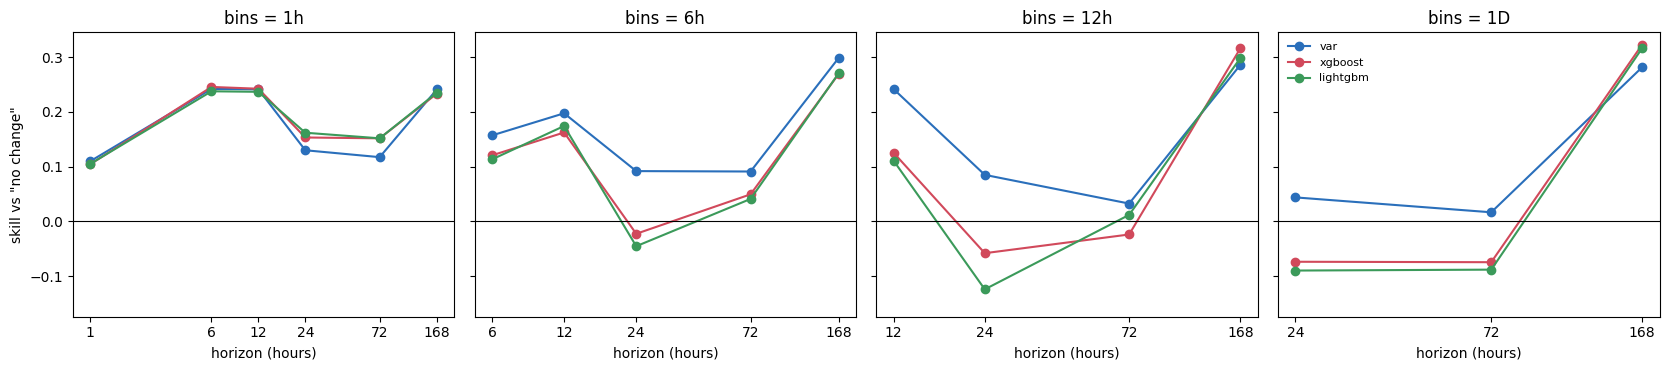

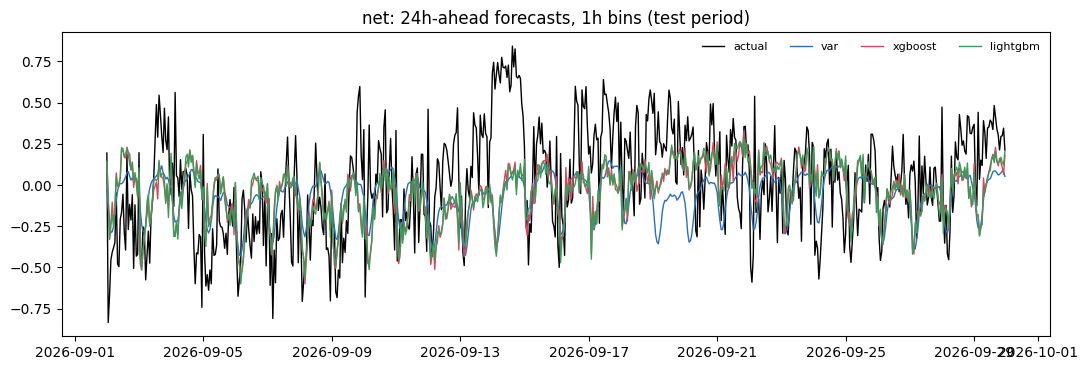

Saved to /content/drive/MyDrive/sentiment_project/results


In [11]:
models = [m for m in ('var', 'xgboost', 'lightgbm') if m in PRED]
SCORES = pd.concat([score(m) for m in models], ignore_index=True)
SCORES.to_csv(f'{OUT_DIR}/scores.csv', index=False)
pd.concat(PRED.values(), ignore_index=True).drop(columns='origin').to_csv(
    f'{OUT_DIR}/predictions.csv', index=False)

print('Skill vs "no change" (above 0 = better):')
display(SCORES.pivot_table(index=['freq', 'horizon_h'], columns='model', values='skill',
                           sort=False)[models].round(3))

colors = {'var': '#2a6fbb', 'xgboost': '#d1495b', 'lightgbm': '#3b9a5a'}
fig, axes = plt.subplots(1, len(DATA), figsize=(4.2 * len(DATA), 3.8), sharey=True, squeeze=False)
for ax, fq in zip(axes[0], DATA):
    g = SCORES[SCORES.freq == fq]
    for m in models:
        gm = g[g.model == m].sort_values('horizon_h')
        ax.plot(gm.horizon_h, gm.skill, marker='o', label=m, color=colors[m])
    hs = sorted(g.horizon_h.unique())
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xscale('log'); ax.set_xticks(hs); ax.set_xticklabels(hs); ax.minorticks_off()
    ax.set_title(f'bins = {fq}'); ax.set_xlabel('horizon (hours)')
axes[0][0].set_ylabel('skill vs "no change"')
axes[0][0].set_ylim(max(-1, SCORES.skill.min() - 0.05), None)
axes[0][-1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/skill_by_horizon.png', dpi=140); plt.show()

# example: 24h-ahead forecasts with the finest bins
fq = list(DATA)[0]; h = 24
fig, ax = plt.subplots(figsize=(11, 3.8))
ref = PRED['persistence'].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
ax.plot(ref.origin_time + pd.Timedelta(hours=h), ref.y_true, color='k', lw=1, label='actual')
for m in models:
    g = PRED[m].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
    ax.plot(g.origin_time + pd.Timedelta(hours=h), g.y_pred, lw=1, label=m, color=colors[m])
ax.set_title(f'{TARGET}: {h}h-ahead forecasts, {fq} bins (test period)')
ax.legend(frameon=False, ncol=4, fontsize=8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/forecast_example.png', dpi=140); plt.show()
print('Saved to', os.path.abspath(OUT_DIR))

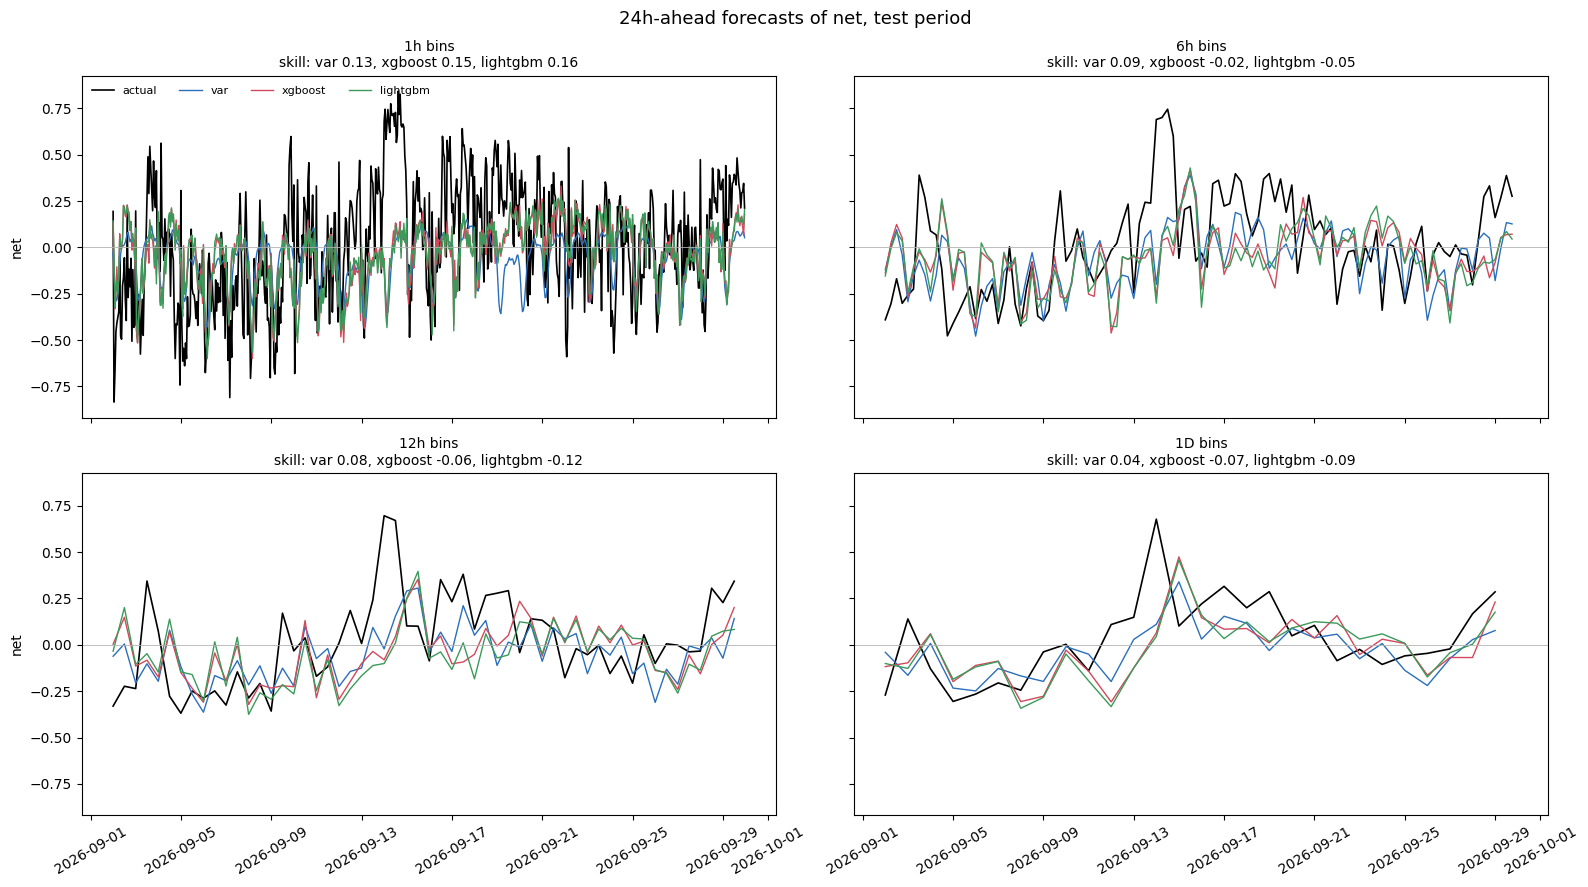

In [12]:
# 24h-ahead forecasts: the four bin sizes in a 2x2 grid
# top left = 1h, top right = 6h, bottom left = 12h, bottom right = 1D
h = 24
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
for ax, fq in zip(axes.ravel(), DATA):
    ref = PRED['persistence'].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
    if ref.empty:
        ax.set_title(f'{fq} bins: no {h}h horizon'); continue
    ax.plot(ref.origin_time + pd.Timedelta(hours=h), ref.y_true, color='k', lw=1.2, label='actual')
    for m in models:
        g = PRED[m].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
        ax.plot(g.origin_time + pd.Timedelta(hours=h), g.y_pred, lw=1, label=m, color=colors[m])
    ax.axhline(0, color='0.7', lw=0.6)
    sk = SCORES.query('freq == @fq and horizon_h == @h').set_index('model').skill
    ax.set_title(f'{fq} bins\nskill: ' + ', '.join(f'{m} {sk[m]:.2f}' for m in models if m in sk),
                 fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel(TARGET)
for ax in axes[1]:
    ax.tick_params(axis='x', labelrotation=30)
for ax in axes.ravel()[len(DATA):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, ncol=4, fontsize=8, loc='upper left')
fig.suptitle(f'{h}h-ahead forecasts of {TARGET}, test period', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/forecast_all_bins.png', dpi=140, bbox_inches='tight'); plt.show()

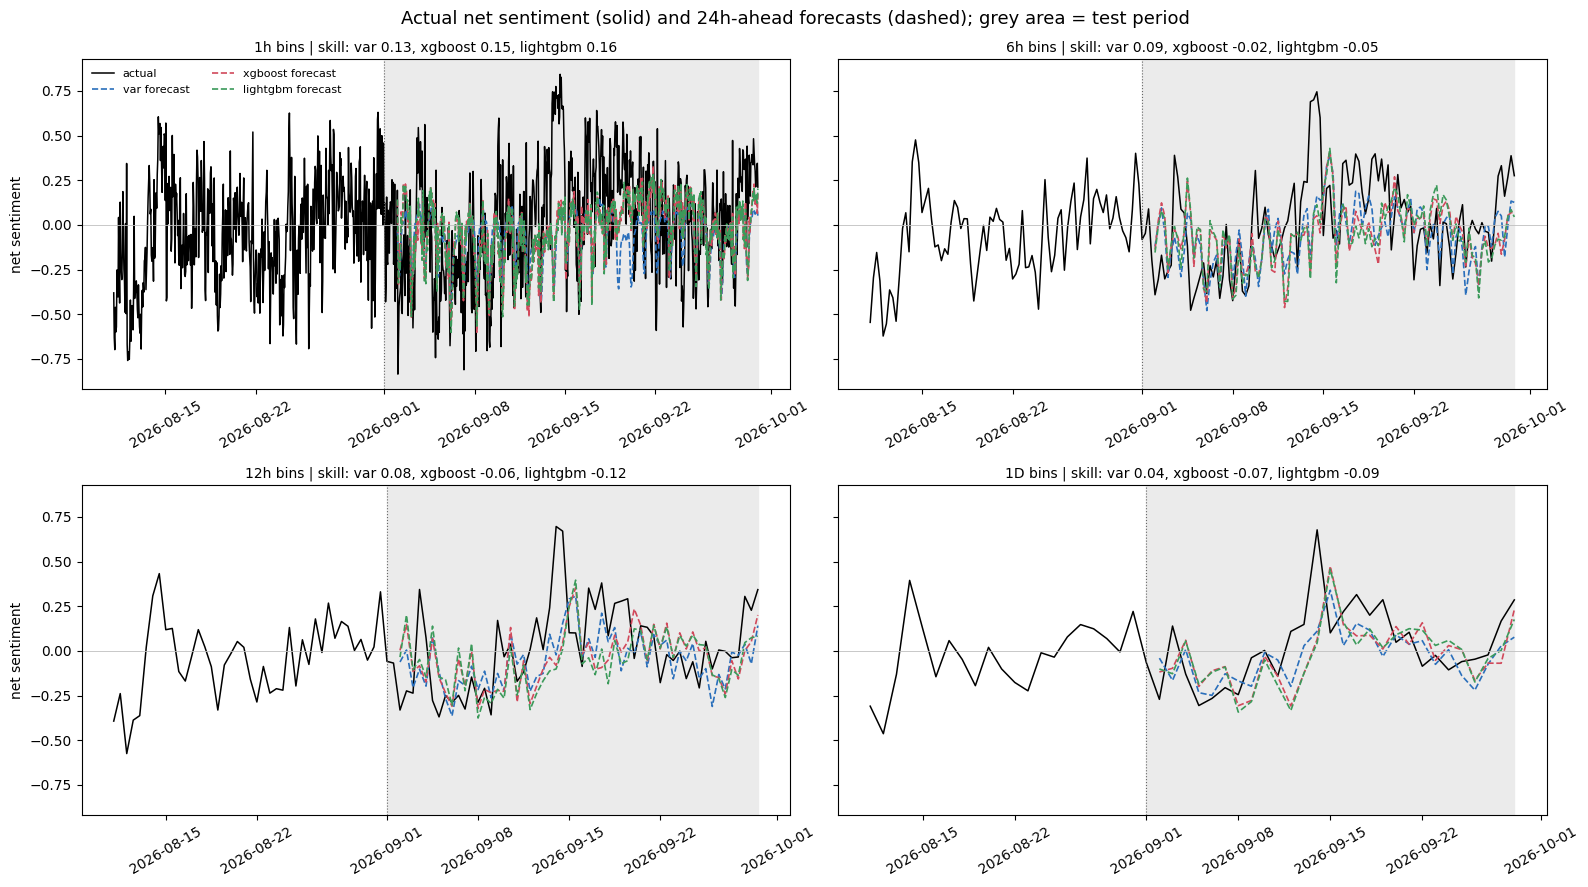

In [13]:
# ===== Forecast vs actual track, 2x2 grid =====
# Solid line   = actual net sentiment (part of the training period + the whole test period)
# Dashed lines = forecasts of each model, placed at the time they forecast (forecast time + horizon)
# Top left = 1h, top right = 6h, bottom left = 12h, bottom right = 1D
H_PLOT      = 24     # horizon to show (hours): 24, 72 or 168 exist for every bin size
DAYS_BEFORE = 21     # how many days of actual data before the test period to show

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)
for ax, fq in zip(axes.ravel(), DATA):
    D = DATA[fq]
    # --- actual track (solid)
    start = TEST_START_TS - pd.Timedelta(days=DAYS_BEFORE)
    actual = pd.Series(D['y'], index=D['times'])
    actual = actual[actual.index >= start]
    ax.plot(actual.index, actual.values, color='k', lw=1.1, label='actual')
    # --- forecasts (dashed)
    for m in models:
        g = PRED[m].query('freq == @fq and horizon_h == @H_PLOT').sort_values('origin_time')
        if g.empty:
            continue
        ax.plot(g.origin_time + pd.Timedelta(hours=H_PLOT), g.y_pred,
                ls='--', lw=1.2, color=colors[m], label=f'{m} forecast')
    # --- mark the test period
    ax.axvspan(TEST_START_TS, actual.index[-1], color='0.92', zorder=0)
    ax.axvline(TEST_START_TS, color='0.4', lw=0.8, ls=':')
    ax.axhline(0, color='0.75', lw=0.6)
    sk = SCORES.query('freq == @fq and horizon_h == @H_PLOT').set_index('model').skill
    ax.set_title(f'{fq} bins | skill: ' + ', '.join(f'{m} {sk[m]:.2f}' for m in models if m in sk),
                 fontsize=10)
    ax.tick_params(axis='x', labelrotation=30)
for ax in axes[:, 0]:
    ax.set_ylabel(f'{TARGET} sentiment')
for ax in axes.ravel()[len(DATA):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, ncol=2, fontsize=8, loc='upper left')
fig.suptitle(f'Actual net sentiment (solid) and {H_PLOT}h-ahead forecasts (dashed); '
             f'grey area = test period', fontsize=13)
fig.tight_layout()
fig.savefig(f'{OUT_DIR}/forecast_track_{H_PLOT}h.png', dpi=140, bbox_inches='tight')
plt.show()

In [14]:
# ===== Extra evaluation metrics for =====
#  MAE        average size of the error (same unit as the target)
#  RMSE       like MAE but punishes big misses more
#  bias       average error; > 0 = model forecasts too high on average
#  R2         1 - SSE/SST on the test period (1 = perfect, 0 = no better than the test mean,
#             can be negative)
#  corr       correlation between forecast and actual (pattern match, ignores level)
#  dir_acc    share of forecasts that get the DIRECTION of change right (up vs down)
#  skill      1 - MAE / MAE("no change")
rows = []
pers = PRED['persistence'][['freq', 'horizon_h', 'origin', 'y_pred']].rename(columns={'y_pred': 'y_now'})
for m in models:
    P = PRED[m].merge(pers, on=['freq', 'horizon_h', 'origin'])
    for (fq, h), g in P.groupby(['freq', 'horizon_h'], sort=False):
        e = g.y_pred - g.y_true
        sst = ((g.y_true - g.y_true.mean()) ** 2).sum()
        moved = (g.y_true - g.y_now) != 0
        rows.append(dict(
            freq=fq, horizon_h=h, model=m,
            MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()), bias=e.mean(),
            R2=1 - (e ** 2).sum() / sst,
            corr=np.corrcoef(g.y_pred, g.y_true)[0, 1],
            dir_acc=(np.sign(g.y_pred - g.y_now) == np.sign(g.y_true - g.y_now))[moved].mean()))
METRICS = pd.DataFrame(rows).merge(SCORES[['freq', 'horizon_h', 'model', 'skill']],
                                   on=['freq', 'horizon_h', 'model'])
METRICS.to_csv(f'{OUT_DIR}/metrics.csv', index=False)
for col in ('MAE', 'RMSE', 'R2', 'dir_acc'):
    print(f'\n{col}')
    display(METRICS.pivot_table(index=['freq', 'horizon_h'], columns='model', values=col,
                                sort=False)[models].round(3))
print('\nAll metrics saved to', f'{OUT_DIR}/metrics.csv')


MAE


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.173    0.174     0.174
     6          0.207    0.206     0.208
     12         0.231    0.230     0.232
     24         0.254    0.247     0.245
     72         0.260    0.249     0.249
     168        0.268    0.270     0.270
6h   6          0.132    0.138     0.139
     12         0.162    0.169     0.166
     24         0.195    0.219     0.224
     72         0.211    0.221     0.223
     168        0.231    0.241     0.240
12h  12         0.124    0.143     0.145
     24         0.174    0.202     0.214
     72         0.194    0.205     0.198
     168        0.217    0.208     0.213
1D   24         0.151    0.170     0.172
     72         0.174    0.191     0.193
     168        0.207    0.195     0.197


RMSE


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.221    0.219     0.220
     6          0.260    0.259     0.263
     12         0.287    0.290     0.290
     24         0.315    0.308     0.308
     72         0.325    0.313     0.315
     168        0.334    0.340     0.341
6h   6          0.179    0.179     0.181
     12         0.210    0.221     0.217
     24         0.245    0.273     0.275
     72         0.276    0.284     0.286
     168        0.303    0.324     0.328
12h  12         0.169    0.192     0.193
     24         0.222    0.252     0.267
     72         0.250    0.269     0.263
     168        0.277    0.285     0.291
1D   24         0.191    0.216     0.220
     72         0.233    0.255     0.254
     168        0.269    0.255     0.262


R2


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.513    0.520     0.518
     6          0.327    0.332     0.313
     12         0.183    0.170     0.167
     24         0.025    0.068     0.072
     72        -0.064    0.009    -0.004
     168       -0.227   -0.271    -0.275
6h   6          0.522    0.522     0.508
     12         0.346    0.272     0.300
     24         0.119   -0.098    -0.108
     72        -0.154   -0.219    -0.237
     168       -0.565   -0.784    -0.827
12h  12         0.497    0.353     0.348
     24         0.152   -0.096    -0.227
     72        -0.125   -0.302    -0.248
     168       -0.583   -0.673    -0.743
1D   24         0.213   -0.012    -0.046
     72        -0.193   -0.426    -0.408
     168       -0.903   -0.709    -0.802


dir_acc


model             var  xgboost  lightgbm
freq horizon_h                          
1h   1          0.665    0.694     0.701
     6          0.732    0.761     0.745
     12         0.751    0.779     0.776
     24         0.702    0.683     0.699
     72         0.708    0.708     0.713
     168        0.742    0.744     0.748
6h   6          0.704    0.713     0.696
     12         0.737    0.754     0.754
     24         0.580    0.634     0.652
     72         0.654    0.644     0.644
     168        0.761    0.693     0.716
12h  12         0.825    0.737     0.754
     24         0.643    0.589     0.589
     72         0.577    0.577     0.635
     168        0.795    0.705     0.705
1D   24         0.500    0.571     0.643
     72         0.654    0.654     0.615
     168        0.727    0.727     0.727


All metrics saved to results/metrics.csv


Method: mean |SHAP| | horizon 24h | share_% = share of total importance

Share of importance by feature group (%)


group          net history  other shares  post volume  calendar
freq model                                                     
1h   xgboost          52.8          14.7         11.8      20.6
     lightgbm         52.3          15.7         11.1      20.8
6h   xgboost          52.0          15.3         18.3      14.4
     lightgbm         50.5          16.1         18.4      14.9
12h  xgboost          57.5          12.5         18.5      11.5
     lightgbm         56.8          11.9         19.4      11.9
1D   xgboost          49.6          21.6         15.6      13.2
     lightgbm         48.5          17.3         20.0      14.1

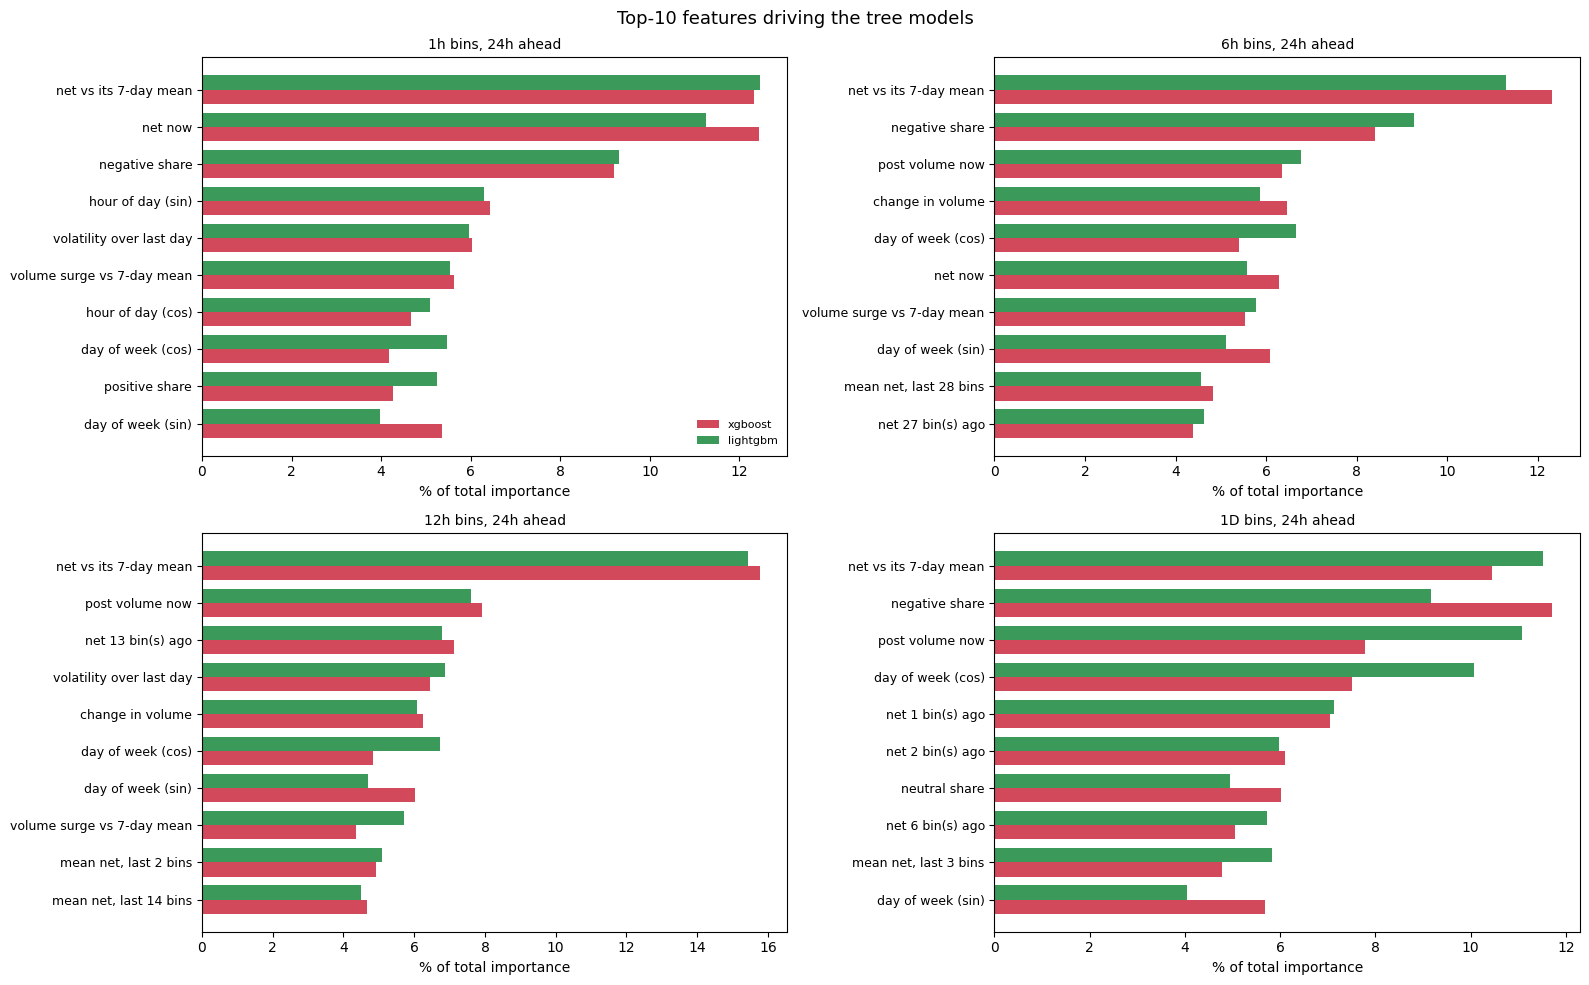

In [15]:
# ===== 13. Which features drive XGBoost / LightGBM? =====
# Uses the models fitted in cells 6-7 (last test fold) and explains their forecasts
# on the test period with SHAP values: how much each feature moves the forecast, on average.
H_EXPLAIN = 24          # horizon (hours) to explain; must exist for the bin sizes

FEATURE_INFO = {
    'y_lag0': 'net now', 'y_diff1': 'change since last bin', 'y_dev_week': 'net vs its 7-day mean',
    'y_std_day': 'volatility over last day', 'logn': 'post volume now',
    'logn_surge': 'volume surge vs 7-day mean', 'logn_diff1': 'change in volume',
    'share_neu': 'neutral share', 'share_pos': 'positive share', 'share_neg': 'negative share',
    'hour_sin': 'hour of day (sin)', 'hour_cos': 'hour of day (cos)',
    'dow_sin': 'day of week (sin)', 'dow_cos': 'day of week (cos)', 'is_empty': 'empty bin flag'}
def describe(f):
    if f in FEATURE_INFO: return FEATURE_INFO[f]
    if f.startswith('y_lag'): return f'net {f[5:]} bin(s) ago'
    if f.startswith('y_mean'): return f'mean net, last {f[6:]} bins'
    return f
def feature_group(f):
    if f.startswith('y_'): return f'{TARGET} history'
    if f.startswith('logn') or f == 'is_empty': return 'post volume'
    if f.startswith('share'): return 'other shares'
    return 'calendar'

def importance(name, m, X, y_delta):
    """mean |SHAP| (native in xgboost / lightgbm); falls back to permutation importance."""
    try:
        if name == 'xgboost':
            c = m.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
        else:
            c = m.predict(X, pred_contrib=True)
        return np.abs(np.asarray(c)[:, :-1]).mean(0), 'mean |SHAP|'
    except Exception:
        from sklearn.inspection import permutation_importance
        r = permutation_importance(m, X, y_delta, n_repeats=5, random_state=0,
                                   scoring='neg_mean_absolute_error')
        return np.clip(r.importances_mean, 0, None), 'permutation importance'

IMP_ROWS = []
for fq, D in DATA.items():
    s = H_EXPLAIN // D['hours']
    if H_EXPLAIN % D['hours']:
        continue
    idx = np.where((D['times'] >= TEST_START_TS) & D['valid'] & (np.arange(D['T']) + s < D['T']))[0]
    Xt, yd = D['X'][idx], D['y'][idx + s] - D['y'][idx]
    for name, store in (('xgboost', XGB_MODELS), ('lightgbm', LGB_MODELS)):
        m = store.get((fq, H_EXPLAIN))
        if m is None:
            continue
        imp, how = importance(name, m, Xt, yd)
        for f, v in zip(D['feature_names'], imp):
            IMP_ROWS.append(dict(freq=fq, model=name, feature=f, description=describe(f),
                                 group=feature_group(f), importance=v, method=how))
IMP = pd.DataFrame(IMP_ROWS)
IMP['share_%'] = 100 * IMP.importance / IMP.groupby(['freq', 'model']).importance.transform('sum')
IMP.to_csv(f'{OUT_DIR}/feature_importance_trees.csv', index=False)
print(f'Method: {IMP.method.iloc[0]} | horizon {H_EXPLAIN}h | share_% = share of total importance\n')

# importance by feature group (comparable with the VAR breakdown in cell 14)
TREE_GROUP_SHARE = IMP.pivot_table(index=['freq', 'model'], columns='group', values='share_%',
                                   aggfunc='sum', sort=False).round(1)
print('Share of importance by feature group (%)')
display(TREE_GROUP_SHARE)

# top-10 features per bin size: 2x2 grid, xgboost and lightgbm side by side
freqs_imp = list(dict.fromkeys(IMP.freq))
fig, axes = plt.subplots(2, 2, figsize=(16, 10), squeeze=False)
for ax, fq in zip(axes.ravel(), freqs_imp):
    g = IMP[IMP.freq == fq]
    top = g.groupby('description')['share_%'].mean().nlargest(10).index[::-1]
    yy = np.arange(len(top))
    for j, name in enumerate(('xgboost', 'lightgbm')):
        v = g[g.model == name].set_index('description')['share_%'].reindex(top).fillna(0)
        ax.barh(yy + (j - 0.5) * 0.38, v, height=0.38, color=colors[name], label=name)
    ax.set_yticks(yy); ax.set_yticklabels(top, fontsize=9)
    ax.set_xlabel('% of total importance'); ax.set_title(f'{fq} bins, {H_EXPLAIN}h ahead', fontsize=10)
for ax in axes.ravel()[len(freqs_imp):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8, loc='lower right')
fig.suptitle('Top-10 features driving the tree models', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/feature_importance_trees.png', dpi=140, bbox_inches='tight'); plt.show()

FEVD: where the uncertainty of the NET forecast comes from (% , rows sum to 100)


p  post volume  neutral share  net sentiment
freq horizon_h                                              
1h   24         7         23.9            6.7           69.5
     168        7         23.6            7.0           69.4
6h   24         4          2.9           14.7           82.4
     168        4          9.1           16.1           74.8
12h  24         2          0.2           17.0           82.8
     168        2          6.3           16.9           76.8
1D   24         1          2.6           23.0           74.4
     168        1          4.7           24.8           70.5


Granger causality (p < 0.05 = the cause helps predict the effect)


freq                               1h        6h       12h        1D
cause         effect                                               
neutral share net sentiment    0.0166     0.945     0.511     0.646
              post volume    2.09e-06     0.192     0.684     0.546
post volume   net sentiment   0.00048  0.000126    0.0639   0.00522
              neutral share   0.00018   0.00651   0.00224  0.000557
net sentiment neutral share  5.69e-05     0.337     0.323    0.0914
              post volume    4.22e-11  2.07e-06  0.000302    0.0411


Half-life of a shock to net sentiment (hours until its effect is halved):
{'1h': 1, '6h': 12, '12h': 36, '1D': 48}


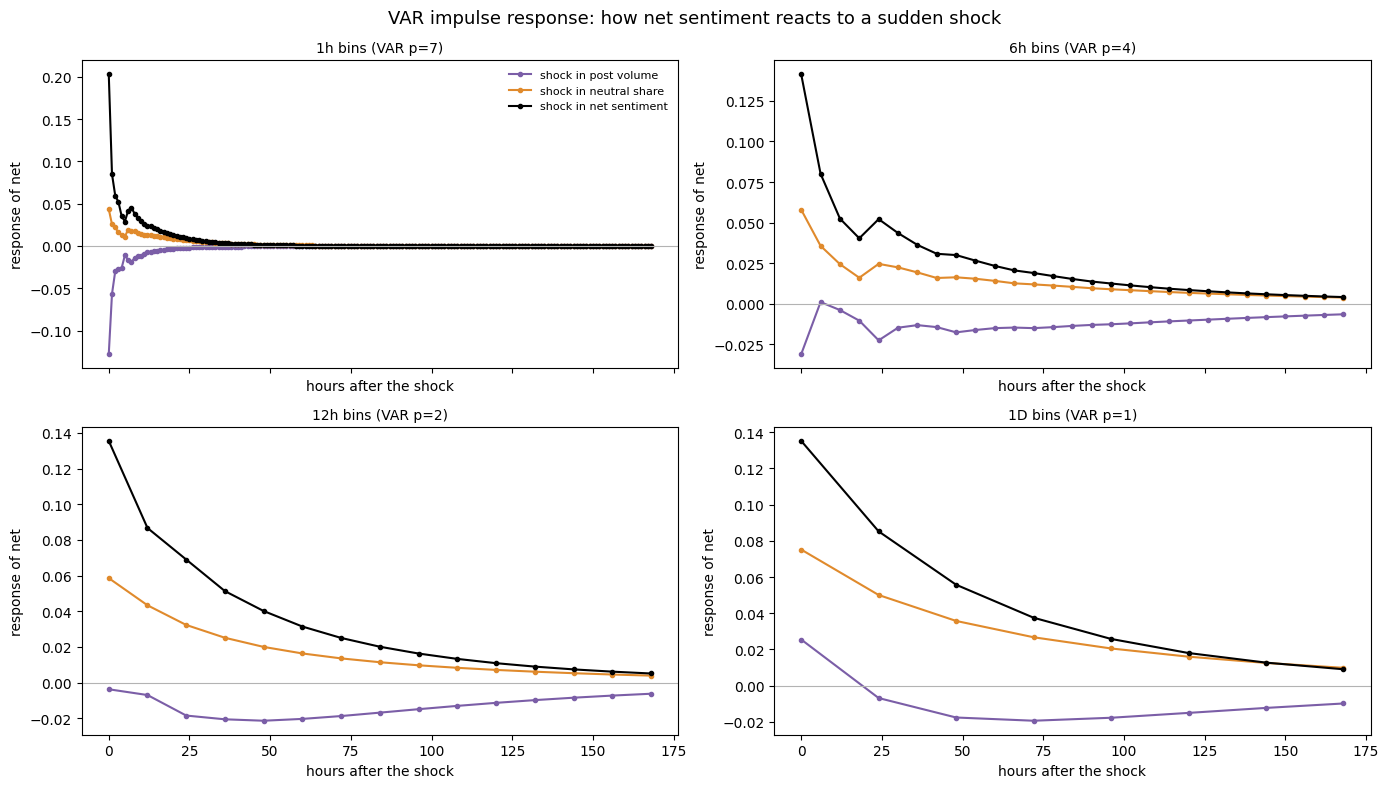


Comparison (different methods, compare the ranking rather than the exact %):
    1h | VAR FEVD: own net 70%, volume 24%, neutral 7%  | trees (xgb): net history 53%, volume 12%, shares 15%, calendar 21%
    6h | VAR FEVD: own net 82%, volume 3%, neutral 15%  | trees (xgb): net history 52%, volume 18%, shares 15%, calendar 14%
   12h | VAR FEVD: own net 83%, volume 0%, neutral 17%  | trees (xgb): net history 58%, volume 18%, shares 12%, calendar 12%
    1D | VAR FEVD: own net 74%, volume 3%, neutral 23%  | trees (xgb): net history 50%, volume 16%, shares 22%, calendar 13%


In [16]:
# ===== 14. What drives VAR? (FEVD, Granger causality, impulse response) =====
# VAR has no "features"; its equivalents are:
#  FEVD     % of the uncertainty in the net forecast that comes from shocks to each variable
#  Granger  does variable X help predict net (beyond net's own past)? p < 0.05 = yes
#  IRF      how net responds over time when one variable gets a sudden 1-SD shock
# Shocks are separated with a Cholesky ordering: volume first, then neutral share, then net
# (net may react within the same bin to volume and neutral; not the other way round).
# The daily/weekly rhythm (sine/cosine terms) is a fixed pattern and not part of these numbers.
from scipy import stats

VAR_ORDER = ['logn', 'share_neu', 'net']
NAMES = {'logn': 'post volume', 'share_neu': 'neutral share', 'net': 'net sentiment'}
H_LIST = [24, 168]
IRF_DAYS = 7

def ma_coefs(A, n):
    k = A[0].shape[0]; Phi = [np.eye(k)]
    for s in range(1, n):
        Phi.append(sum(A[i] @ Phi[s - 1 - i] for i in range(min(s, len(A)))))
    return Phi

FEVD_ROWS, GRANGER_ROWS, IRF = [], [], {}
for fq, D in DATA.items():
    hours, times = D['hours'], D['times']
    T0 = int(np.searchsorted(times, TEST_START_TS))
    Z = D['agg'][VAR_VARS].to_numpy(float); E = fourier_terms(times, hours)
    p, Bv = fit_var(Z, E, T0, P_MAX.get(hours, 7))
    k, ne = Z.shape[1], E.shape[1]; off = 1 + ne
    rows = np.arange(p, T0)
    Xu = var_design(Z, E, p, rows); R = Z[rows] - Xu @ Bv
    Sigma = R.T @ R / len(rows)
    A = [Bv[off + L * k: off + (L + 1) * k, :].T for L in range(p)]
    o = [VAR_VARS.index(v) for v in VAR_ORDER]
    A_o = [a[np.ix_(o, o)] for a in A]
    P = np.linalg.cholesky(Sigma[np.ix_(o, o)])
    n_steps = max(IRF_DAYS * 24 // hours, max(H_LIST) // hours) + 1
    theta = [Ph @ P for Ph in ma_coefs(A_o, n_steps)]          # orthogonalised responses
    i_net = VAR_ORDER.index('net')
    # FEVD of net
    for h in H_LIST:
        H = h // hours
        if h % hours or H < 1: continue
        contrib = np.array([sum(theta[s][i_net, j] ** 2 for s in range(H)) for j in range(k)])
        FEVD_ROWS.append(dict(freq=fq, horizon_h=h, p=p,
                              **{NAMES[v]: 100 * contrib[j] / contrib.sum() for j, v in enumerate(VAR_ORDER)}))
    # Granger causality: every ordered pair
    for c in VAR_VARS:
        ic = VAR_VARS.index(c)
        ssr_u = ((Z[rows, ic] - Xu @ np.linalg.lstsq(Xu, Z[rows, ic], rcond=None)[0]) ** 2).sum()
        for g_ in VAR_VARS:
            if g_ == c: continue
            ig = VAR_VARS.index(g_)
            drop = [off + L * k + ig for L in range(p)]
            Xr = np.delete(Xu, drop, axis=1)
            ssr_r = ((Z[rows, ic] - Xr @ np.linalg.lstsq(Xr, Z[rows, ic], rcond=None)[0]) ** 2).sum()
            df2 = len(rows) - Xu.shape[1]
            F = ((ssr_r - ssr_u) / p) / (ssr_u / df2)
            GRANGER_ROWS.append(dict(freq=fq, cause=NAMES[g_], effect=NAMES[c], F=F,
                                     p_value=stats.f.sf(F, p, df2)))
    # IRF of net, and half-life of a shock to net itself
    own = np.array([theta[s][i_net, i_net] for s in range(n_steps)])
    below = np.where(np.abs(own) <= 0.5 * abs(own[0]))[0]
    IRF[fq] = dict(hours=hours, theta=theta, p=p,
                   half_life_h=(int(below[0] * hours) if len(below) else None))

FEVD = pd.DataFrame(FEVD_ROWS).round(1)
GRANGER = pd.DataFrame(GRANGER_ROWS)
GRANGER['significant'] = np.where(GRANGER.p_value < 0.05, 'yes', 'no')
FEVD.to_csv(f'{OUT_DIR}/var_fevd.csv', index=False); GRANGER.to_csv(f'{OUT_DIR}/var_granger.csv', index=False)

print('FEVD: where the uncertainty of the NET forecast comes from (% , rows sum to 100)')
display(FEVD.set_index(['freq', 'horizon_h']))
print('\nGranger causality (p < 0.05 = the cause helps predict the effect)')
display(GRANGER.pivot_table(index=['cause', 'effect'], columns='freq', values='p_value',
                            sort=False)[list(DATA)].map(lambda v: f'{v:.3g}'))
print('\nHalf-life of a shock to net sentiment (hours until its effect is halved):')
print({fq: v['half_life_h'] for fq, v in IRF.items()})

# IRF plot: response of net to a 1-SD shock in each variable, 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, squeeze=False)
shock_col = {'logn': '#7b5ea7', 'share_neu': '#e08a2c', 'net': 'k'}
for ax, (fq, v) in zip(axes.ravel(), IRF.items()):
    n = IRF_DAYS * 24 // v['hours'] + 1
    x = np.arange(n) * v['hours']
    for j, var in enumerate(VAR_ORDER):
        ax.plot(x, [v['theta'][s][i_net, j] for s in range(n)], marker='o', ms=3,
                color=shock_col[var], label=f'shock in {NAMES[var]}')
    ax.axhline(0, color='0.7', lw=0.8)
    ax.set_title(f'{fq} bins (VAR p={v["p"]})', fontsize=10)
    ax.set_xlabel('hours after the shock'); ax.set_ylabel('response of net')
for ax in axes.ravel()[len(IRF):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle('VAR impulse response: how net sentiment reacts to a sudden shock', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/var_impulse_response.png', dpi=140, bbox_inches='tight'); plt.show()

# side-by-side summary with the tree models (if cell 13 was run)
if 'TREE_GROUP_SHARE' in globals():
    print('\nComparison (different methods, compare the ranking rather than the exact %):')
    for fq in DATA:
        f24 = FEVD[(FEVD.freq == fq) & (FEVD.horizon_h == 24)]
        if f24.empty or fq not in TREE_GROUP_SHARE.index.get_level_values(0): continue
        tv = TREE_GROUP_SHARE.loc[fq]
        print(f'  {fq:>4} | VAR FEVD: own net {f24["net sentiment"].iloc[0]:.0f}%, '
              f'volume {f24["post volume"].iloc[0]:.0f}%, neutral {f24["neutral share"].iloc[0]:.0f}%'
              f'  | trees (xgb): net history {tv.loc["xgboost"].get(f"{TARGET} history", 0):.0f}%, '
              f'volume {tv.loc["xgboost"].get("post volume", 0):.0f}%, '
              f'shares {tv.loc["xgboost"].get("other shares", 0):.0f}%, '
              f'calendar {tv.loc["xgboost"].get("calendar", 0):.0f}%')